# Social Media User Churn Prediction Using Machine Learning

## 1.Project Overview

### This project is a machine learning-based Social Media Churn Prediction system that predicts whether a social media user is likely to churn based on their activity and engagement behaviour. The project uses user activity data such as session duration, posts, likes, comments, shares, watch time, notifications, advertisements, engagement score, and habit score.

### The data is preprocessed and analysed using Python, followed by feature selection and machine learning classification. A Gradient Boosting Classifier is used to predict the user's churn status.

### The trained model is integrated into a Flask web application where users can enter the required activity details and receive a churn prediction through a simple web interface.


## 2. Objective:

### The objective of this project is to predict whether a social media user is likely to churn or not based on their activity and engagement behaviour using machine learning.

## 3.Data Description:
### Source: Kaggle – Meta-Style User Dataset
### Features: Average session duration, posts created, likes given, comments made, shares, watch time, notifications clicked, recommended content clicks, ads clicked, engagement score, habit score, age group, device type, followers, weekly active days, days since last engagement, session count, and user ID.
### Target Variable: churn_flag – indicates whether the user has churned or not.

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 4.Data Collection

In [5]:
df=pd.read_csv("meta_dataset.csv")
df.head()

,user_id,age_group,device_type,session_count,avg_session_duration,posts_created,likes_given,comments_made,shares,watch_time,followers,days_since_last_engagement,weekly_active_days,notifications_clicked,recommended_content_clicks,ads_clicked,engagement_score,habit_score,churn_flag
0,3878,18-24,mobile,0,13.722439,0,90,10,19,194.562012,16190,75,1,5,30,21,93.103967,104.802477,1
1,8658,35-44,tablet,3,14.822228,0,61,32,14,NaN,6844,48,3,9,17,4,90.259472,94.917304,0
2,23759,25-34,desktop,0,12.715171,1,101,38,3,136.383023,19056,64,6,11,34,5,191.253345,146.871407,0
3,5295,35-44,desktop,0,14.001196,1,117,21,11,86.693679,15266,81,4,1,21,2,147.980160,173.049880,0
4,16253,35-44,mobile,4,10.423444,1,67,5,5,207.329070,3772,63,6,6,37,11,68.049931,44.475373,1


In [6]:
df.shape

(95000, 19)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95000 entries, 0 to 94999
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   user_id                     95000 non-null  int64  
 1   age_group                   95000 non-null  object 
 2   device_type                 95000 non-null  object 
 3   session_count               95000 non-null  int64  
 4   avg_session_duration        90317 non-null  float64
 5   posts_created               95000 non-null  int64  
 6   likes_given                 95000 non-null  int64  
 7   comments_made               95000 non-null  int64  
 8   shares                      95000 non-null  int64  
 9   watch_time                  90270 non-null  float64
 10  followers                   95000 non-null  int64  
 11  days_since_last_engagement  95000 non-null  int64  
 12  weekly_active_days          95000 non-null  int64  
 13  notifications_clicked       950

In [8]:
df.isnull().sum()

user_id                          0
age_group                        0
device_type                      0
session_count                    0
avg_session_duration          4683
posts_created                    0
likes_given                      0
comments_made                    0
shares                           0
watch_time                    4730
followers                        0
days_since_last_engagement       0
weekly_active_days               0
notifications_clicked            0
recommended_content_clicks       0
ads_clicked                      0
engagement_score              4986
habit_score                      0
churn_flag                       0
dtype: int64

## 5.Data Preprocessing , Data Cleaning

In [9]:
#handling missing values
df["avg_session_duration"]=df["avg_session_duration"].fillna(df["avg_session_duration"].median())
df["watch_time"]=df["watch_time"].fillna(df["watch_time"].median())
df["engagement_score"]=df["engagement_score"].fillna(df["engagement_score"].median())


In [10]:
df.isnull().sum()

user_id                       0
age_group                     0
device_type                   0
session_count                 0
avg_session_duration          0
posts_created                 0
likes_given                   0
comments_made                 0
shares                        0
watch_time                    0
followers                     0
days_since_last_engagement    0
weekly_active_days            0
notifications_clicked         0
recommended_content_clicks    0
ads_clicked                   0
engagement_score              0
habit_score                   0
churn_flag                    0
dtype: int64

In [11]:
df.describe()

,user_id,session_count,avg_session_duration,posts_created,likes_given,comments_made,shares,watch_time,followers,days_since_last_engagement,weekly_active_days,notifications_clicked,recommended_content_clicks,ads_clicked,engagement_score,habit_score,churn_flag
count,95000.000000,95000.000000,95000.000000,95000.000000,95000.000000,95000.000000,95000.000000,95000.000000,95000.000000,95000.000000,95000.000000,95000.000000,95000.000000,95000.000000,95000.000000,95000.000000,95000.000000
mean,15012.050305,2.004389,10.028209,0.704168,59.467232,19.484295,9.509242,149.751393,9995.870526,44.589295,2.993495,12.330179,19.500305,9.957137,89.071083,88.923387,0.433274
std,8650.591453,1.408819,4.760159,0.839126,34.644229,11.534805,5.765110,84.550123,5748.757391,25.967493,2.001705,10.403829,11.541547,8.751016,45.464457,54.898334,0.495530
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001535,50.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7540.000000,1.000000,6.836926,0.000000,30.000000,10.000000,5.000000,78.531211,5041.750000,22.000000,1.000000,4.000000,10.000000,3.000000,56.728908,48.208912,0.000000
50%,14988.000000,2.000000,10.006647,1.000000,59.000000,19.000000,10.000000,149.141502,9985.000000,45.000000,3.000000,10.000000,19.000000,8.000000,88.669018,81.467756,0.000000
75%,22506.000000,3.000000,13.143852,1.000000,89.000000,29.000000,15.000000,220.924015,14951.000000,67.000000,5.000000,19.000000,30.000000,15.000000,120.524501,122.379663,1.000000
max,29999.000000,11.000000,29.568021,6.000000,119.000000,39.000000,19.000000,299.995885,19999.000000,89.000000,6.000000,47.000000,39.000000,39.000000,264.944864,369.092466,1.000000


## Check for and remove outliers using statistical methods.

In [13]:
num_cols = df.select_dtypes(include='number').columns.drop(['user_id', 'churn_flag'])

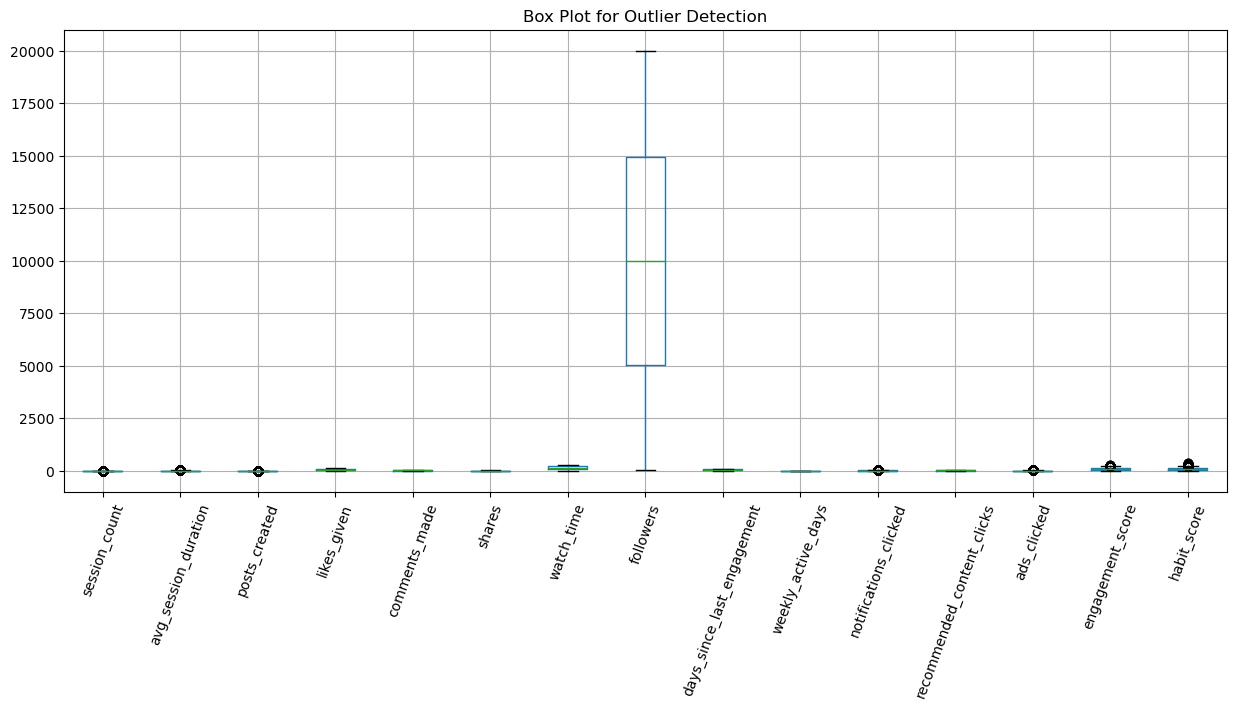

In [14]:
df[num_cols].boxplot(figsize=(15, 6))
plt.xticks(rotation=70)
plt.title('Box Plot for Outlier Detection')
plt.show()

In [15]:
df["age_group"].value_counts()

age_group
45+      23883
18-24    23812
35-44    23798
25-34    23507
Name: count, dtype: int64

In [16]:
df["age_group"].unique()

array(['18-24', '35-44', '25-34', '45+'], dtype=object)

In [17]:
df['device_type'].value_counts()

device_type
mobile     31903
tablet     31588
desktop    31509
Name: count, dtype: int64

In [18]:
df['device_type'].unique()

array(['mobile', 'tablet', 'desktop'], dtype=object)

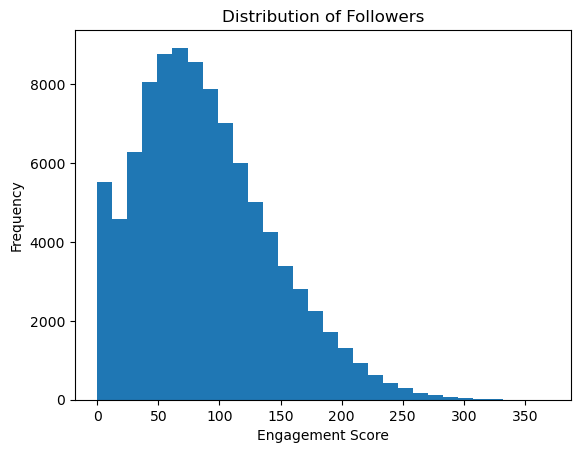

In [19]:
plt.hist(df['habit_score'], bins=30)
plt.xlabel('Engagement Score')
plt.ylabel('Frequency')
plt.title('Distribution of Followers')
plt.show()

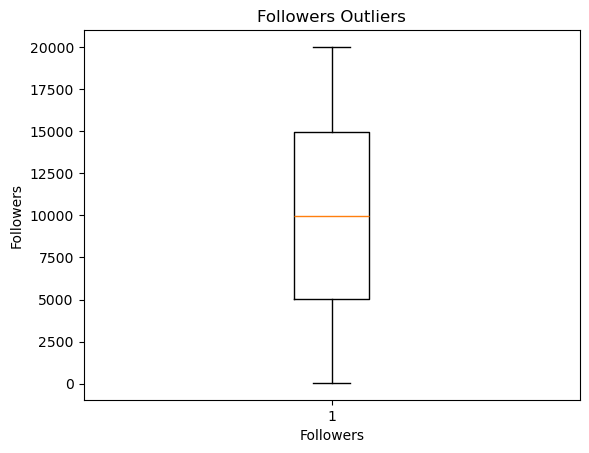

In [20]:
plt.boxplot(df['followers'])
plt.title('Followers Outliers')
plt.ylabel('Followers')
plt.xlabel('Followers')
plt.show()

### Removing outliers using statistical method.

In [21]:
#IQR
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_clean = df[~((df[num_cols] < lower) | (df[num_cols] > upper)).any(axis=1)]

In [22]:
df.shape

(95000, 19)

In [23]:
df_clean.shape

(87797, 19)

## Address skewed data in numerical features through transformations.  

In [24]:
df_clean[num_cols].skew()

session_count                 0.554051
avg_session_duration          0.017815
posts_created                 0.694722
likes_given                   0.020421
comments_made                 0.015478
shares                        0.003526
watch_time                    0.006210
followers                     0.006686
days_since_last_engagement   -0.006530
weekly_active_days            0.011945
notifications_clicked         0.853171
recommended_content_clicks    0.002717
ads_clicked                   0.855610
engagement_score              0.044627
habit_score                   0.478974
dtype: float64

In [25]:
#square root transformation
df_clean['session_count'] = np.sqrt(df_clean['session_count'])
df_clean['posts_created'] = np.sqrt(df_clean['posts_created'])
df_clean['notifications_clicked'] = np.sqrt(df_clean['notifications_clicked'])
df_clean['ads_clicked'] = np.sqrt(df_clean['ads_clicked'])

C:\Users\diane\AppData\Local\Temp\ipykernel_22020\196728414.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['session_count'] = np.sqrt(df_clean['session_count'])
C:\Users\diane\AppData\Local\Temp\ipykernel_22020\196728414.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['posts_created'] = np.sqrt(df_clean['posts_created'])
C:\Users\diane\AppData\Local\Temp\ipykernel_22020\196728414.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try 

In [26]:
df_clean[num_cols].skew()

session_count                -0.723251
avg_session_duration          0.017815
posts_created                 0.209496
likes_given                   0.020421
comments_made                 0.015478
shares                        0.003526
watch_time                    0.006210
followers                     0.006686
days_since_last_engagement   -0.006530
weekly_active_days            0.011945
notifications_clicked        -0.043877
recommended_content_clicks    0.002717
ads_clicked                  -0.048249
engagement_score              0.044627
habit_score                   0.478974
dtype: float64

In [27]:
df_clean['session_count'] = df_clean['session_count'] ** 2

C:\Users\diane\AppData\Local\Temp\ipykernel_22020\1297263582.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['session_count'] = df_clean['session_count'] ** 2


In [28]:
df_clean[num_cols].skew()

session_count                 0.554051
avg_session_duration          0.017815
posts_created                 0.209496
likes_given                   0.020421
comments_made                 0.015478
shares                        0.003526
watch_time                    0.006210
followers                     0.006686
days_since_last_engagement   -0.006530
weekly_active_days            0.011945
notifications_clicked        -0.043877
recommended_content_clicks    0.002717
ads_clicked                  -0.048249
engagement_score              0.044627
habit_score                   0.478974
dtype: float64

## 6.Exploratory Data Analysis (EDA)

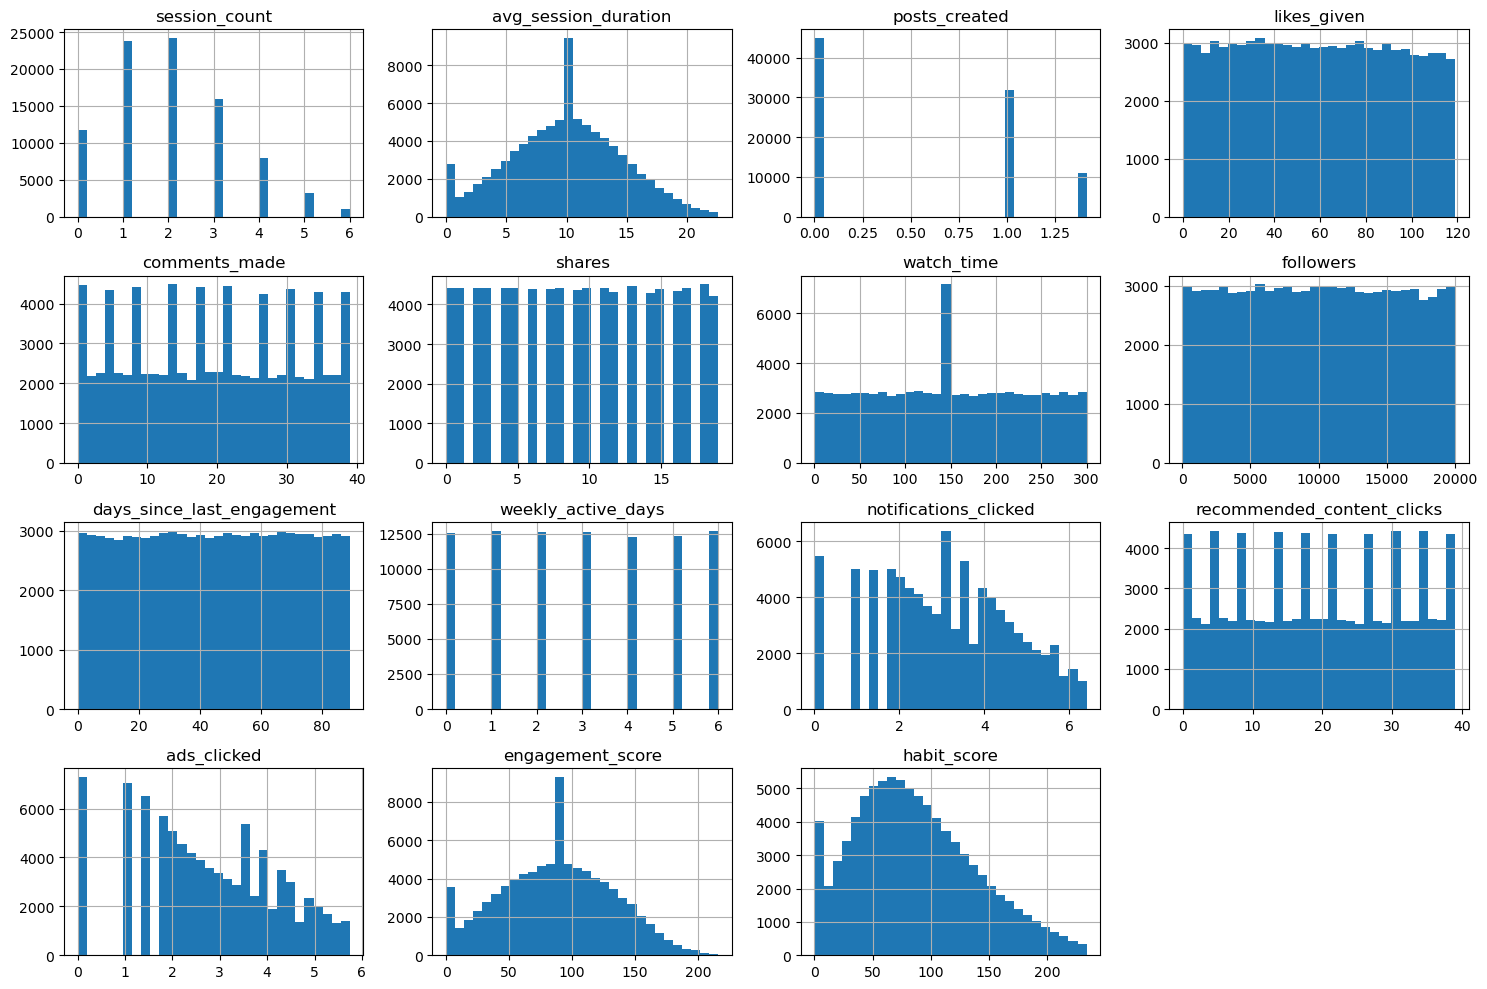

In [29]:
df_clean[num_cols].hist(figsize=(15,10), bins=30)

plt.tight_layout()
plt.show()

In [30]:
print(len(num_cols))
print(num_cols)

15
Index(['session_count', 'avg_session_duration', 'posts_created', 'likes_given',
       'comments_made', 'shares', 'watch_time', 'followers',
       'days_since_last_engagement', 'weekly_active_days',
       'notifications_clicked', 'recommended_content_clicks', 'ads_clicked',
       'engagement_score', 'habit_score'],
      dtype='object')


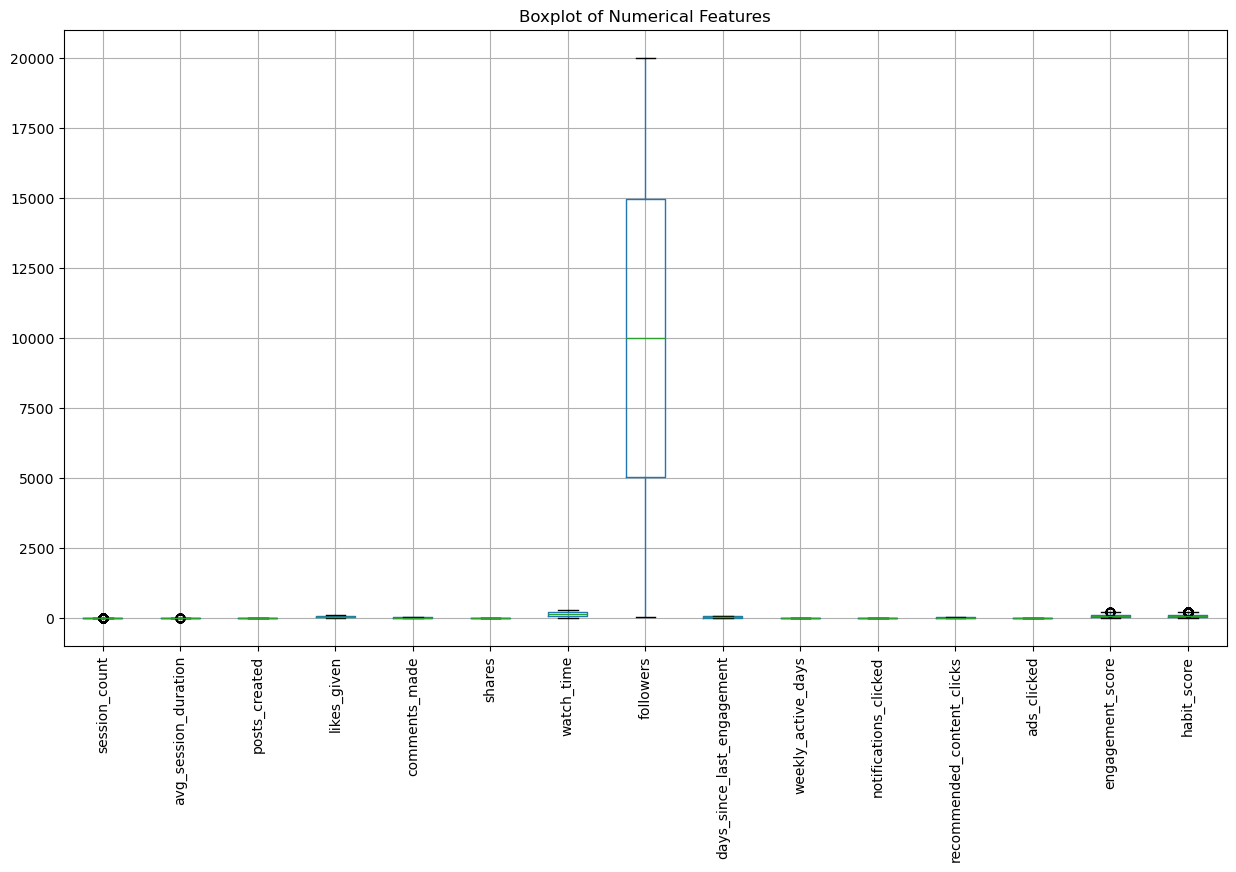

In [31]:
plt.figure(figsize=(15,8))

df_clean[num_cols].boxplot()

plt.xticks(rotation=90)
plt.title('Boxplot of Numerical Features')
plt.show()

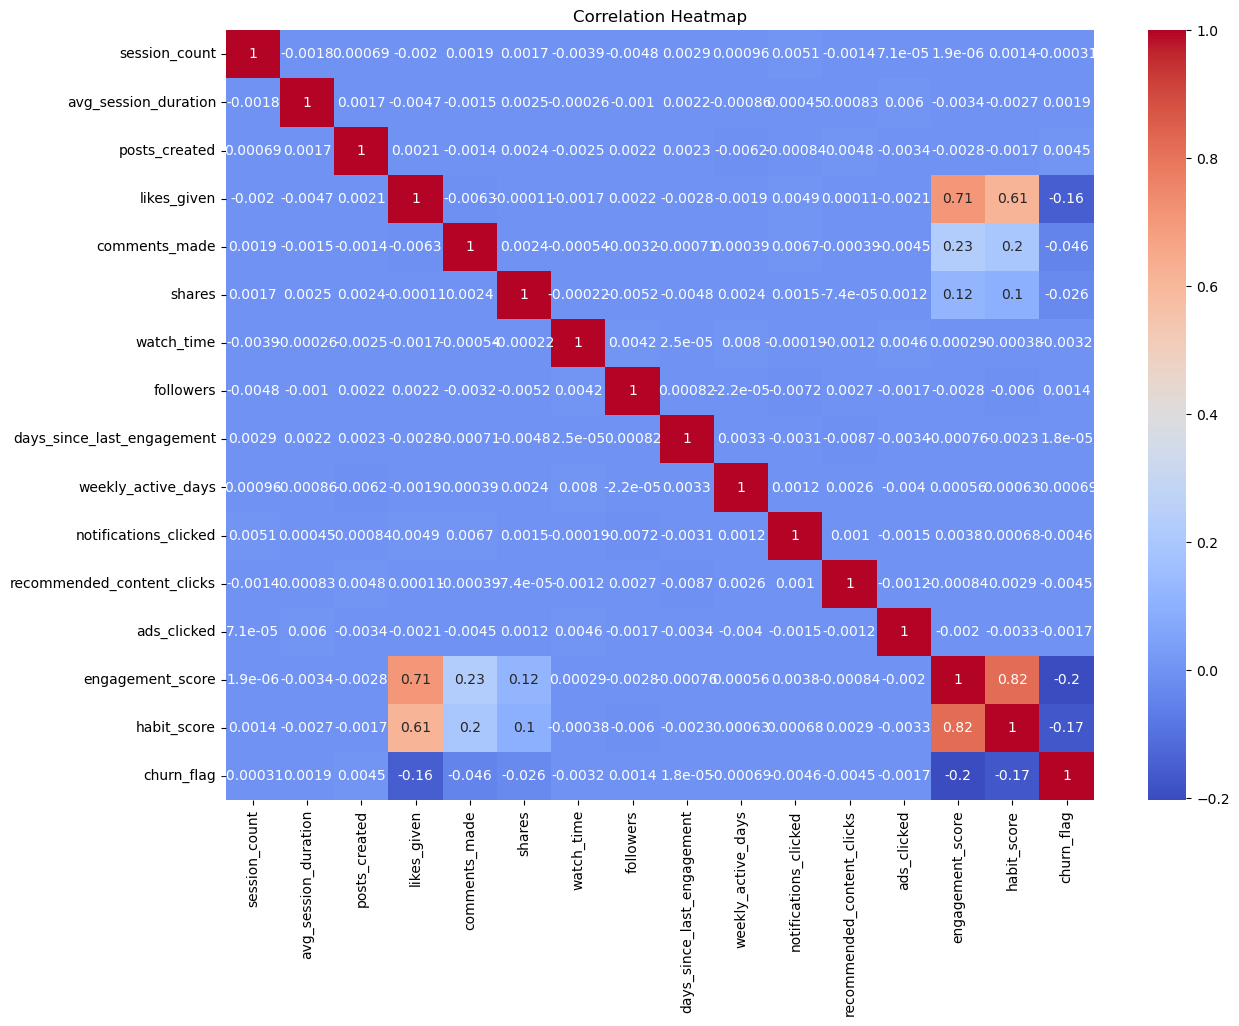

In [32]:
corr_cols = list(num_cols) + ['churn_flag']

plt.figure(figsize=(14,10))

sns.heatmap(df_clean[corr_cols].corr(),annot=True,cmap='coolwarm')

plt.title('Correlation Heatmap')
plt.show()

### The chart shows a very strong connection between a user's engagement_score and habit_score (0.82), which means that user habits on the platform heavily match their overall activity. Giving likes (likes_given) is also strongly connected to higher engagement and habit scores. Interestingly, most other metrics like post creation and watch time do not affect each other, meaning they represent completely separate user behaviors.

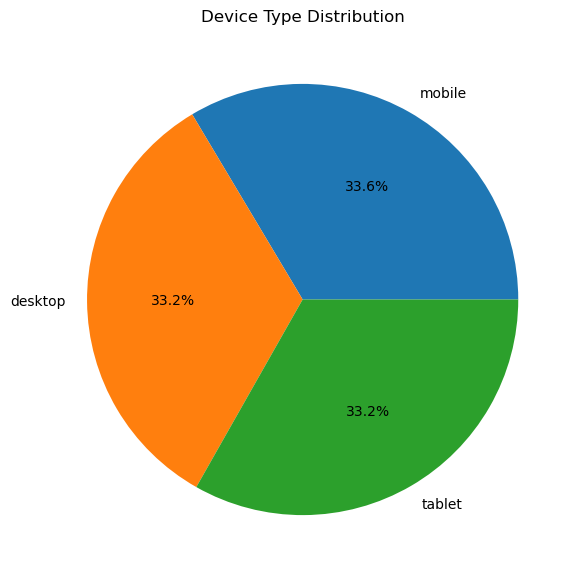

In [33]:
device_counts = df_clean['device_type'].value_counts()

plt.figure(figsize=(7,7))
plt.pie(
    device_counts,
    labels=device_counts.index,
    autopct='%1.1f%%'
)

plt.title('Device Type Distribution')
plt.show()

#### The user base is split almost perfectly into three equal parts among mobile (33.6%), desktop (33.2%), and tablet (33.2%) users.

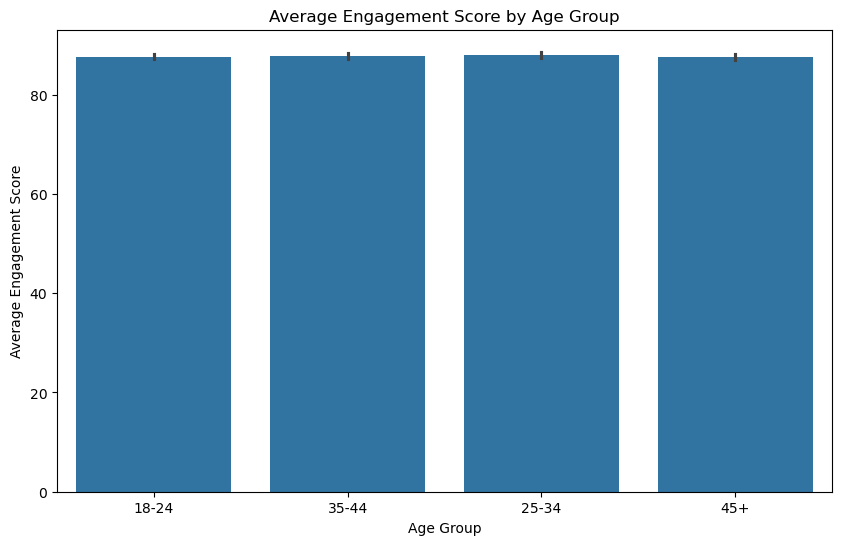

In [36]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=df_clean,
    x='age_group',
    y='engagement_score'
)

plt.title('Average Engagement Score by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Engagement Score')
plt.show()

#### The average engagement score is virtually identical across all age groups, staying right around 88 points for everyone from age 18 to over 45. This tells us that a user's age has no impact on how much they interact with the platform, and the app appeals equally to all generations.

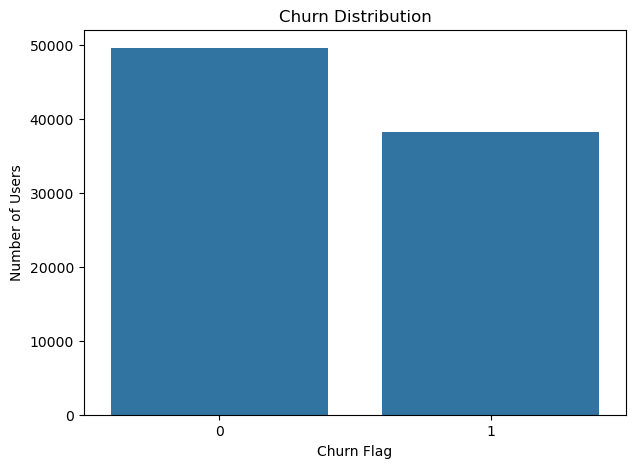

In [37]:
plt.figure(figsize=(7,5))

sns.countplot(data=df_clean, x='churn_flag')

plt.title('Churn Distribution')
plt.xlabel('Churn Flag')
plt.ylabel('Number of Users')
plt.show()

#### The dataset contains a healthy mix of both active and churned users, though there are slightly more active users. There are roughly 50,000 active users (0) compared to about 38,000 users who have left (1). This distribution gives the machine learning model plenty of examples of both classes to learn from without requiring complex balancing fixes.

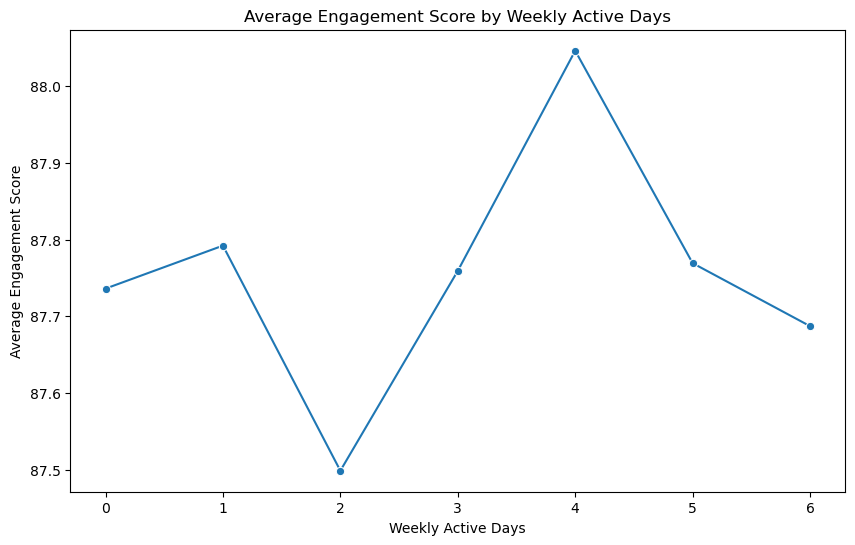

In [40]:
line_data = df_clean.groupby('weekly_active_days')['engagement_score'].mean().reset_index()

plt.figure(figsize=(10,6))

sns.lineplot(
    data=line_data,
    x='weekly_active_days',
    y='engagement_score',
    marker='o'
)

plt.title('Average Engagement Score by Weekly Active Days')
plt.xlabel('Weekly Active Days')
plt.ylabel('Average Engagement Score')
plt.show()

#### While the line graph looks like it has sharp ups and downs, the actual change on the left axis is incredibly small—ranging only between 87.5 and 88 points. This means that the number of active days in a week barely changes a user's engagement score, keeping it stable regardless of how many days they log in.

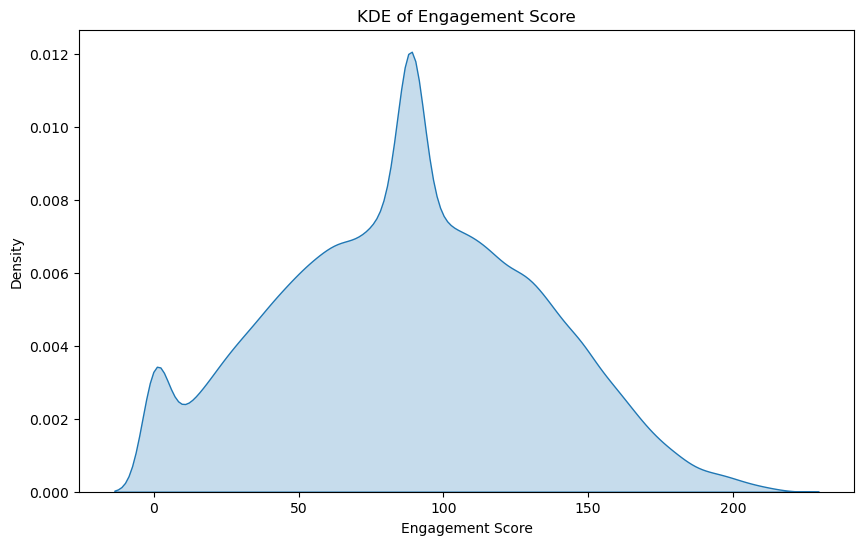

In [41]:
plt.figure(figsize=(10,6))

sns.kdeplot(
    data=df_clean,
    x='engagement_score',
    fill=True
)

plt.title('KDE of Engagement Score')
plt.xlabel('Engagement Score')
plt.ylabel('Density')
plt.show()

#### The engagement score does not follow a normal, smooth bell curve and instead has three separate peaks. There is a small group of users stuck near a score of 0, a massive main group of users peaked right around a score of 90, and a long tail of highly active users stretching out past a score of 150.

## 7. **Feature Engineering:**    - 
### Identify and encode categorical features using techniques like one-hot encoding or label encoding.

In [42]:
cat_cols = ['age_group', 'device_type']
print(df_clean[cat_cols].head())

  age_group device_type
0     18-24      mobile
1     35-44      tablet
2     25-34     desktop
3     35-44     desktop
4     35-44      mobile


## one-hot encoding

In [50]:
df_encoded = pd.get_dummies(
    df_clean,
    columns=cat_cols,
    drop_first=True,dtype=int
)
df_encoded.head()


,user_id,session_count,avg_session_duration,posts_created,likes_given,comments_made,shares,watch_time,followers,days_since_last_engagement,...,recommended_content_clicks,ads_clicked,engagement_score,habit_score,churn_flag,age_group_25-34,age_group_35-44,age_group_45+,device_type_mobile,device_type_tablet
0,3878,0.0,13.722439,0.0,90,10,19,194.562012,16190,75,...,30,4.582576,93.103967,104.802477,1,0,0,0,1,0
1,8658,3.0,14.822228,0.0,61,32,14,149.141502,6844,48,...,17,2.000000,90.259472,94.917304,0,0,1,0,0,1
2,23759,0.0,12.715171,1.0,101,38,3,136.383023,19056,64,...,34,2.236068,191.253345,146.871407,0,1,0,0,0,0
3,5295,0.0,14.001196,1.0,117,21,11,86.693679,15266,81,...,21,1.414214,147.980160,173.049880,0,0,1,0,0,0
4,16253,4.0,10.423444,1.0,67,5,5,207.329070,3772,63,...,37,3.316625,68.049931,44.475373,1,0,1,0,1,0


In [55]:
x = df_encoded.drop(columns=['user_id', 'churn_flag'])
y= df_encoded['churn_flag']

In [56]:
x.shape

(87797, 20)

In [57]:
y.shape

(87797,)

## 8.Feature Selection

In [59]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(x, y)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [62]:
importance = pd.DataFrame({
    'Feature': x.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)
print(importance)

                       Feature  Importance
13            engagement_score    0.098748
14                 habit_score    0.090486
7                    followers    0.080899
6                   watch_time    0.079537
1         avg_session_duration    0.078696
3                  likes_given    0.074598
8   days_since_last_engagement    0.070386
11  recommended_content_clicks    0.062372
4                comments_made    0.060819
10       notifications_clicked    0.059915
12                 ads_clicked    0.057469
5                       shares    0.050778
9           weekly_active_days    0.036212
0                session_count    0.032673
2                posts_created    0.017781
18          device_type_mobile    0.010450
19          device_type_tablet    0.010371
15             age_group_25-34    0.009341
16             age_group_35-44    0.009287
17               age_group_45+    0.009183


In [67]:
#SelectKBest
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=14)

x_selected = selector.fit_transform(x, y)
selected_features = x.columns[selector.get_support()]

selected_features

Index(['avg_session_duration', 'posts_created', 'likes_given', 'comments_made',
       'shares', 'watch_time', 'notifications_clicked',
       'recommended_content_clicks', 'ads_clicked', 'engagement_score',
       'habit_score', 'age_group_25-34', 'age_group_35-44', 'age_group_45+'],
      dtype='object')

In [69]:
new_x = x[selected_features]
new_x.shape

(87797, 14)

In [70]:
y.shape

(87797,)

## 9.Split Data into Training and Testing Sets.

In [71]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(new_x,y,test_size=0.2,
    random_state=42,
    stratify=y
)

In [73]:
x_train.shape

(70237, 14)

In [76]:
x_test.shape

(17560, 14)

In [74]:
y_train.shape

(70237,)

In [75]:
y_test.shape

(17560,)

## 10.Feature Scaling

In [77]:
#Standardization
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

## 11.Build the ML Model

In [81]:
from sklearn.metrics import accuracy_score

In [82]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(x_train_scaled, y_train)
y_pred = model.predict(x_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
accuracy

0.5995444191343964

In [83]:
#Decision Tree
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)
model.fit(x_train_scaled, y_train)
y_pred = model.predict(x_test_scaled)

decision_tree_accuracy = accuracy_score(y_test, y_pred)

decision_tree_accuracy

0.5298405466970387

In [84]:
#Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
model.fit(x_train_scaled, y_train)
y_pred = model.predict(x_test_scaled)

random_forest_accuracy = accuracy_score(y_test, y_pred)

random_forest_accuracy

0.5882687927107062

In [86]:
#KNN
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=5)
model.fit(x_train_scaled, y_train)
y_pred = model.predict(x_test_scaled)
                       
knn_accuracy = accuracy_score(y_test, y_pred)

knn_accuracy

0.548120728929385

In [94]:
#Gradient Boost Classifier
from sklearn.ensemble import GradientBoostingClassifier

model = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42
)
model.fit(x_train_scaled, y_train)
# y_pred = model.predict(x_test_scaled)
# Get probability of class 1 (churn)
y_prob = model.predict_proba(x_test_scaled)[:, 1]

# Change threshold from 0.5 to 0.4
y_pred_new = (y_prob >= 0.4).astype(int)

gradient_boost_accuracy = accuracy_score(y_test, y_pred)

gradient_boost_accuracy

0.6030182232346242

## 12. Model evaluation

In [97]:
from sklearn.metrics import confusion_matrix

cmatrix = confusion_matrix(y_test, y_pred_new)
cmatrix

array([[4899, 5019],
       [2494, 5148]])

In [99]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision_new = precision_score(y_test, y_pred_new)
recall_new = recall_score(y_test, y_pred_new)
f1_new = f1_score(y_test, y_pred_new)

print("Precision:", precision_new)
print("Recall:", recall_new)
print("F1-Score:", f1_new)

Precision: 0.5063440542933019
Recall: 0.6736456425019628
F1-Score: 0.5781346510191476


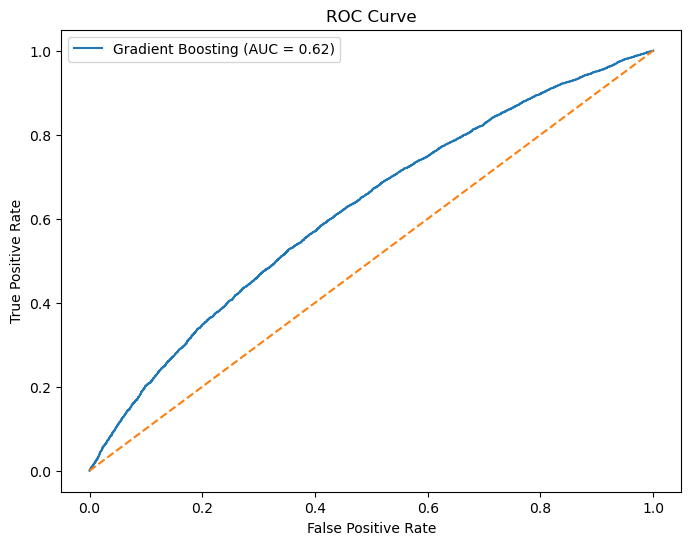

AUC: 0.6190604028669742


In [100]:
from sklearn.metrics import roc_curve, auc


y_prob = model.predict_proba(x_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Gradient Boosting (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

print("AUC:", roc_auc)

## 13. Hyperparameter Tuning and  pipeline

In [103]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([
    ('model', GradientBoostingClassifier(random_state=42))
])

param_grid = {
    'model__n_estimators': [50],
    'model__learning_rate': [0.1],
    'model__max_depth': [2, 3]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=3,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(x_train_scaled, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV Recall:")
print(grid_search.best_score_)

Fitting 3 folds for each of 2 candidates, totalling 6 fits
Best Parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 50}
Best CV Recall:
0.34837096379249965


In [104]:
y_pred_tuned = grid_search.predict(x_test_scaled)

print("Test Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Test Precision:", precision_score(y_test, y_pred_tuned))
print("Test Recall:", recall_score(y_test, y_pred_tuned))
print("Test F1-Score:", f1_score(y_test, y_pred_tuned))

Test Accuracy: 0.6016514806378133
Test Precision: 0.5711145306660804
Test Recall: 0.3399633603768647
Test F1-Score: 0.4262160610286277


## 14. Save the Model.

In [105]:
import joblib

# Save the trained model
joblib.dump(grid_search.best_estimator_, 'churn_model.joblib')

print("Model saved successfully!")

Model saved successfully!


## 15. Test with Unseen Data

In [106]:
import joblib
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Load the saved model
model_loaded = joblib.load('churn_model.joblib')

# Predict on unseen test data
y_pred_unseen = model_loaded.predict(x_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_unseen))
print("Precision:", precision_score(y_test, y_pred_unseen))
print("Recall:", recall_score(y_test, y_pred_unseen))
print("F1-Score:", f1_score(y_test, y_pred_unseen))

Accuracy: 0.6016514806378133
Precision: 0.5711145306660804
Recall: 0.3399633603768647
F1-Score: 0.4262160610286277


## 16. Conclusion


### The Gradient Boosting model performed best among the models tested. After hyperparameter tuning, it achieved **60.17% accuracy, 57.11% precision, 34.00% recall, and 42.62% F1-score**. The model can predict churn to some extent, but the low recall shows that it misses many actual churners.

### The main limitation is that the dataset is **simulated**, so it may not completely represent real-world social media behaviour. The model could be improved using real-world data, more relevant features, and further tuning.

### Overall, the project successfully demonstrates the complete machine learning process from preprocessing to model evaluation and saving the final model.


In [109]:
import joblib

joblib.dump(scaler, 'scaler.joblib')

print("Scaler saved successfully!")

Scaler saved successfully!
